# Tabular Foundation Models: TabPFN on an Equity Cross-Section

## Introduction

Every other notebook in this course trains a model on your data. This one does not.

**TabPFN** is a transformer that was pre-trained once, on millions of *synthetic* tabular
datasets, to do Bayesian inference in a single forward pass. You hand it a training set and a
test set together, and it returns a predictive distribution without ever updating a weight.
There is no fitting loop, no learning rate, and no hyperparameters to tune.

This notebook is the companion to **Transformers III — Transformers for Tabular Data**. The
slides derive the posterior predictive distribution (PPD), explain Prior-Data Fitted Networks
(PFNs), and survey TabPFN v2, TabPFN-TS, TabICL and TabFM. Here we do the thing the slides
cannot: run it on a real financial panel and find out where it helps, where it does not, and
where it stops working altogether.

### Learning Objectives

By the end of this notebook you will be able to:

1. **Explain** why "fit" and "predict" collapse into one forward pass for a PFN, and what is
   being amortized.
2. **Build** a leakage-free cross-sectional equity panel — forward targets, cross-sectional
   standardization, and a temporal split with a gap year.
3. **Compare** zero-shot TabPFN against ElasticNet, Random Forest and XGBoost on the same
   features and the same test set.
4. **Locate** the small-sample regime where in-context learning earns its keep, by sweeping
   the training-set size.
5. **Hit** TabPFN's row-count ceiling deliberately, and explain where it comes from.
6. **Distinguish** a task with signal from one without — and recognise that a strong model
   cannot manufacture predictability that is not there.

### Why tabular, and why finance?

Slide 22 of the lecture makes the claim this notebook tests: *small-data, tabular problems are
the bread and butter of finance*. A monthly equity cross-section is exactly that shape — a few
hundred rows per date, a handful of engineered columns, a low signal-to-noise ratio, and a
regime that drifts. It is the regime where gradient-boosted trees have been the default answer
for a decade, and the regime TabPFN's pre-training prior was designed for.

## 1. Setup

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import io
import time
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import torch BEFORE xgboost and keep it that way.
# Both ship their own copy of the OpenMP runtime. On macOS, if xgboost loads its
# copy first, the kernel dies the moment TabPFN runs its forward pass — a native
# crash, not a Python exception, so you get a dead kernel with no traceback.
# Importing torch first lets it initialise OpenMP and xgboost then reuses it.
import torch

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier
from tabpfn import TabPFNClassifier

warnings.filterwarnings('ignore')

import sys
sys.path.append('../../../')

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

# One fixed colour per model, assigned to the entity and never reindexed.
PALETTE = {
    "TabPFN":       "#2a78d6",
    "XGBoost":      "#eb6834",
    "RandomForest": "#1baf7a",
    "ElasticNet":   "#eda100",
}
MARKERS = {"TabPFN": "o", "XGBoost": "s", "RandomForest": "^", "ElasticNet": "D"}

RANDOM_STATE = 0
print("TabPFN runs on CPU here; every timing below is CPU wall-clock.")

TabPFN runs on CPU here; every timing below is CPU wall-clock.


## 2. What TabPFN is actually doing

A classical Bayesian treatment of supervised learning asks for the posterior predictive
distribution,

$$p(y \mid x, D) = \int p(y \mid x, \theta)\, p(\theta \mid D)\, d\theta,$$

and the integral is the problem: for any interesting hypothesis space it is intractable, so we
approximate it per dataset — MCMC, variational inference, or we give up on the posterior and
point-estimate $\theta$ by minimising a loss.

A **Prior-Data Fitted Network** inverts the loop. Sample a dataset from a prior over datasets,
hide some rows, and train a transformer to predict them from the rows it can see. Repeat
millions of times. The network is not learning one dataset — it is learning *the mapping from a
dataset to its predictive distribution*. At inference you pay one forward pass, and the
posterior comes out the other side.

Two consequences matter for what follows:

- **The training set is an input, not a parameter.** Rows are passed as context, which is why
  there is no `fit` in the usual sense and why positional encodings over rows are dropped —
  a table's rows are a set, not a sequence.
- **The prior is the model.** TabPFN's accuracy on your data is a statement about how well your
  problem resembles the synthetic structural-causal-model prior it was trained on. That is the
  honest caveat behind every number in this notebook.

The cost is quadratic attention over the context, and the context *is* your training set. That
single fact produces the ceiling we hit in Section 6.

## 3. An honest cross-sectional panel

We use the published course dataset: S&P 500 daily adjusted closes with sector metadata, the
same file the final project is built on.

Three guards against look-ahead, which matter more than the model choice:

1. **Targets are strictly forward.** Features are computed from data up to and including month
   end $t$; the label is realised over $t \to t+1$. Nothing on the right-hand side touches the
   future.
2. **Features are standardized within each date.** A cross-sectional z-score per month removes
   the market-wide level, so the model learns relative ranking rather than "2008 was volatile."
   It also means no information crosses between dates.
3. **The split is temporal, with a gap year.** Train on 2005–2014, discard 2015, test on
   2016–2020. The gap absorbs the 12-month trailing windows, so no test-set month shares a
   rolling window with a training month.

In [3]:
DATA = "../../../final_project/sp500_prices_with_metadata.parquet.zip"

t0 = time.time()
with zipfile.ZipFile(DATA) as z:
    raw = pd.read_parquet(
        io.BytesIO(z.read("sp500_prices_with_metadata.parquet")),
        columns=["date", "ticker", "sector", "adj_close", "volume"],
    )
raw["date"] = pd.to_datetime(raw["date"])
raw = raw[raw["date"] >= "2003-01-01"]

px = raw.pivot_table(index="date", columns="ticker", values="adj_close")
shares = raw.pivot_table(index="date", columns="ticker", values="volume")
sector = raw.drop_duplicates("ticker").set_index("ticker")["sector"]

print(f"loaded {len(raw):,} rows in {time.time() - t0:.1f}s")
print(f"wide price matrix: {px.shape[0]} dates x {px.shape[1]} tickers")
print(f"coverage: {px.index.min().date()} -> {px.index.max().date()}")

loaded 2,058,401 rows in 1.2s
wide price matrix: 4507 dates x 504 tickers
coverage: 2003-01-02 -> 2020-11-24


In [4]:
d_ret = px.pct_change()
m_px = px.resample("ME").last()

def trailing_return(n_months):
    return m_px / m_px.shift(n_months) - 1.0

def realised_vol(window):
    """Daily realised vol over a trailing window, sampled at month end."""
    return d_ret.rolling(window).std().resample("ME").last()

features = {
    "vol_1m":        realised_vol(21),
    "vol_3m":        realised_vol(63),
    "vol_12m":       realised_vol(252),
    "vol_ratio":     realised_vol(21) / realised_vol(63),
    "mom_1m":        trailing_return(1),
    "mom_12m":       trailing_return(12),
    "dist_high_12m": m_px / m_px.rolling(12).max() - 1.0,
    "dollar_vol":    np.log((shares * px).rolling(21).mean().resample("ME").last() + 1.0),
}
FEATS = list(features)

# Forward-looking targets: realised vol over the NEXT 21 trading days, and next month's return.
fwd_vol = d_ret.rolling(21).std().shift(-21).resample("ME").last()
fwd_ret = m_px.shift(-1) / m_px - 1.0

panel = pd.concat(
    [df.stack(future_stack=True).rename(name) for name, df in features.items()], axis=1
)
panel["fwd_vol"] = fwd_vol.stack(future_stack=True)
panel["fwd_ret"] = fwd_ret.stack(future_stack=True)
panel.index.names = ["date", "ticker"]
panel = panel.dropna()
panel["sector"] = panel.index.get_level_values("ticker").map(sector)
panel = panel.dropna(subset=["sector"])

# Cross-sectional standardisation, one date at a time.
by_date = panel.groupby(level="date")
for f in FEATS:
    panel[f] = (panel[f] - by_date[f].transform("mean")) / by_date[f].transform("std")

# Two balanced labels: next-month vol regime, and next-month relative return.
panel["y_vol"] = (panel["fwd_vol"] > by_date["fwd_vol"].transform("median")).astype(int)
panel["y_ret"] = (panel["fwd_ret"] > by_date["fwd_ret"].transform("median")).astype(int)
panel = panel.dropna()

print(f"panel: {panel.shape[0]:,} rows x {len(FEATS)} features")
print(f"dates: {panel.index.get_level_values('date').min().date()} -> "
      f"{panel.index.get_level_values('date').max().date()}")
print(f"names per month (median): {int(panel.groupby(level='date').size().median())}")
print(f"label balance -> y_vol {panel.y_vol.mean():.4f} | y_ret {panel.y_ret.mean():.4f}")

panel: 91,707 rows x 8 features
dates: 2004-01-31 -> 2020-10-31
names per month (median): 454
label balance -> y_vol 0.4995 | y_ret 0.4995


In [5]:
dates = panel.index.get_level_values("date")
train = panel[(dates >= "2005-01-01") & (dates <= "2014-12-31")]
test  = panel[(dates >= "2016-01-01") & (dates <= "2020-10-31")]

# TabPFN's cost grows with the test set too, so every model is scored on one
# fixed random slice of the test period. Same rows for every model, always.
N_TEST = 1000
rng = np.random.default_rng(RANDOM_STATE)
test_idx = rng.choice(len(test), size=N_TEST, replace=False)
test_sample = test.iloc[test_idx]

print(f"train: {len(train):,} rows  (2005-2014)")
print(f"test:  {len(test):,} rows  (2016-2020), scored on a fixed {N_TEST}-row slice")
print(f"gap:   2015 discarded")

train: 52,640 rows  (2005-2014)
test:  28,535 rows  (2016-2020), scored on a fixed 1000-row slice
gap:   2015 discarded


## 4. Experiment 1 — zero-shot TabPFN against tuned baselines

A deliberately lopsided comparison. The baselines get sensible, conventional settings. TabPFN
gets nothing: no hyperparameters, no cross-validation, no tuning. We draw 500 training rows —
a realistic sample if you had four years of a 10-name sector book, or one month of the S&P 500.

The task: **will this stock be in the more volatile half of the cross-section next month?**

In [6]:
def make_models(seed=RANDOM_STATE):
    """Fresh, untrained models. Baselines carry conventional settings; TabPFN carries none."""
    return {
        "ElasticNet":   LogisticRegression(penalty="elasticnet", l1_ratio=0.5, solver="saga",
                                           C=1.0, max_iter=2000, random_state=seed),
        "RandomForest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                               random_state=seed, n_jobs=-1),
        "XGBoost":      XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                                      subsample=0.8, colsample_bytree=0.8,
                                      eval_metric="logloss", random_state=seed, n_jobs=-1),
        "TabPFN":       TabPFNClassifier(device="cpu", random_state=seed),
    }

def evaluate(X_tr, y_tr, X_te, y_te, seed=RANDOM_STATE, verbose=True):
    """Fit each model on (X_tr, y_tr) and return test AUC plus wall-clock seconds."""
    out = {}
    for name, model in make_models(seed).items():
        t = time.time()
        model.fit(X_tr, y_tr)
        proba = model.predict_proba(X_te)[:, 1]
        out[name] = {"auc": roc_auc_score(y_te, proba), "seconds": time.time() - t}
        if verbose:
            # TabPFN can take tens of seconds; show progress rather than a dead cell.
            print(f"  {name:<13} {out[name]['seconds']:>6.1f}s  AUC={out[name]['auc']:.4f}", flush=True)
    return out


sub = train.sample(n=500, random_state=RANDOM_STATE)
results_1 = evaluate(sub[FEATS].values, sub["y_vol"].values,
                     test_sample[FEATS].values, test_sample["y_vol"].values)

table_1 = (pd.DataFrame(results_1).T
             .rename(columns={"auc": "test AUC", "seconds": "fit+predict (s)"})
             .sort_values("test AUC", ascending=False))
print("500 training rows, next-month volatility regime\n")
print(table_1.round(4).to_string())

  ElasticNet       0.0s  AUC=0.7855


  RandomForest     0.2s  AUC=0.7853


  XGBoost          0.1s  AUC=0.7713


  TabPFN          16.9s  AUC=0.7909


500 training rows, next-month volatility regime

              test AUC  fit+predict (s)
TabPFN          0.7909          16.8500
ElasticNet      0.7855           0.0062
RandomForest    0.7853           0.2446
XGBoost         0.7713           0.0565


### Reading the table

AUC is the probability that a randomly chosen volatile name is ranked above a randomly chosen
calm one, so 0.5 is a coin flip. Two things are worth noticing, and the second matters more
than the first.

**TabPFN is competitive without being told anything about the problem.** It never saw an equity
panel in pre-training — its prior is synthetic structural causal models — yet it ranks with
models that were given conventional, hand-chosen settings.

**It is also by far the slowest.** The tree models finish in well under a second. TabPFN takes
seconds, on 500 rows, because one "fit" is a forward pass whose context length is the training
set and whose output length is the test set. You are not paying to learn; you are paying to
attend. That trade is excellent when data is scarce and terrible when it is not — which is
precisely what the next two sections measure.

## 5. Experiment 2 — where in-context learning earns its keep

The amortization argument predicts a specific shape: TabPFN should be strongest when $n$ is
small, because a pre-trained prior is worth most when the data cannot speak for itself, and the
advantage should erode as $n$ grows and the trees get enough rows to fit their own structure.

We sweep $n_{\text{train}} \in \{100, 200, 500, 1000\}$ with three independent draws each, and
score every model on the same fixed test slice.

In [7]:
SIZES = [100, 200, 500, 1000]
N_SEEDS = 3

X_te = test_sample[FEATS].values
y_te = test_sample["y_vol"].values

rows = []
t_start = time.time()
for n in SIZES:
    for seed in range(N_SEEDS):
        draw = train.sample(n=n, random_state=1000 + seed)
        res = evaluate(draw[FEATS].values, draw["y_vol"].values, X_te, y_te, seed=seed, verbose=False)
        for name, r in res.items():
            rows.append({"n_train": n, "seed": seed, "model": name, **r})
    done = [r for r in rows if r["n_train"] == n]
    best = max(done, key=lambda r: r["auc"])
    print(f"n_train={n:>5} done ({time.time() - t_start:>5.0f}s elapsed) "
          f"best={best['model']} AUC={best['auc']:.4f}")

sweep = pd.DataFrame(rows)
summary = sweep.pivot_table(index="n_train", columns="model", values="auc", aggfunc="mean")
summary = summary[["TabPFN", "XGBoost", "RandomForest", "ElasticNet"]]
print("\nmean test AUC over 3 draws\n")
print(summary.round(4).to_string())

n_train=  100 done (   23s elapsed) best=ElasticNet AUC=0.7836


n_train=  200 done (   53s elapsed) best=TabPFN AUC=0.7826


n_train=  500 done (  104s elapsed) best=RandomForest AUC=0.7863


n_train= 1000 done (  200s elapsed) best=TabPFN AUC=0.7942

mean test AUC over 3 draws

model    TabPFN  XGBoost  RandomForest  ElasticNet
n_train                                           
100      0.7779   0.7305        0.7584      0.7742
200      0.7801   0.7429        0.7641      0.7733
500      0.7835   0.7595        0.7760      0.7808
1000     0.7887   0.7723        0.7836      0.7843


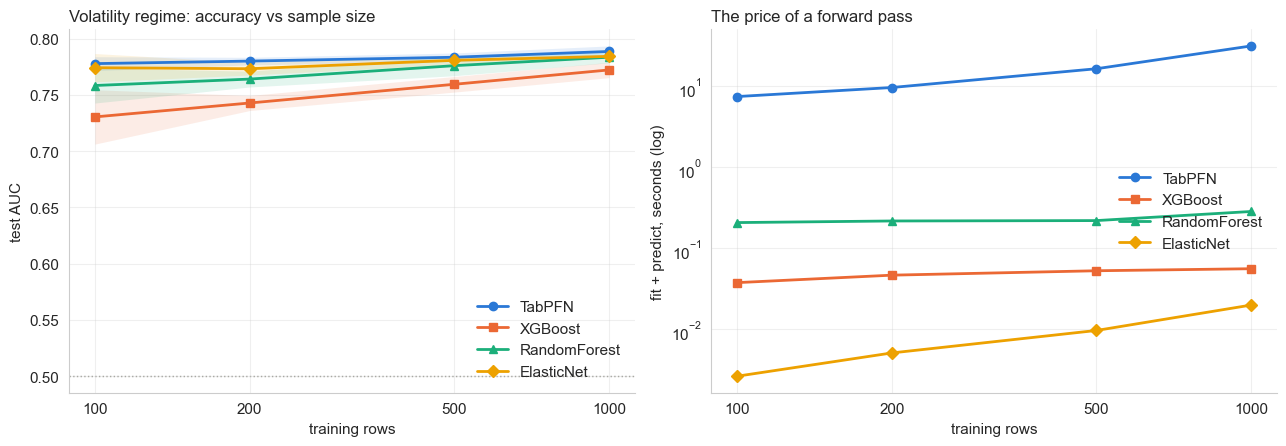

In [8]:
fig, (ax_auc, ax_time) = plt.subplots(1, 2, figsize=(13, 4.6))

for name in ["TabPFN", "XGBoost", "RandomForest", "ElasticNet"]:
    g = sweep[sweep.model == name].groupby("n_train")["auc"]
    mean, sd = g.mean(), g.std()
    ax_auc.plot(mean.index, mean.values, color=PALETTE[name], marker=MARKERS[name],
                markersize=6, linewidth=2, label=name)
    ax_auc.fill_between(mean.index, mean - sd, mean + sd, color=PALETTE[name], alpha=0.12, linewidth=0)

ax_auc.axhline(0.5, color="#9a9a93", linewidth=1, linestyle=":", zorder=0)
ax_auc.set_xscale("log")
ax_auc.set_xticks(SIZES)
ax_auc.set_xticklabels([str(s) for s in SIZES])
ax_auc.set_xlabel("training rows")
ax_auc.set_ylabel("test AUC")
ax_auc.set_title("Volatility regime: accuracy vs sample size", fontsize=12, loc="left")
ax_auc.legend(frameon=False, loc="lower right")

for name in ["TabPFN", "XGBoost", "RandomForest", "ElasticNet"]:
    g = sweep[sweep.model == name].groupby("n_train")["seconds"].mean()
    ax_time.plot(g.index, g.values, color=PALETTE[name], marker=MARKERS[name],
                 markersize=6, linewidth=2, label=name)

ax_time.set_xscale("log")
ax_time.set_yscale("log")
ax_time.set_xticks(SIZES)
ax_time.set_xticklabels([str(s) for s in SIZES])
ax_time.set_xlabel("training rows")
ax_time.set_ylabel("fit + predict, seconds (log)")
ax_time.set_title("The price of a forward pass", fontsize=12, loc="left")
ax_time.legend(frameon=False, loc="center right")

for ax in (ax_auc, ax_time):
    ax.grid(alpha=0.3)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

### Reading the sweep

Two findings, and the second is the one worth arguing about in class.

**Against the tree models, the amortization story holds.** TabPFN leads at every sample size,
and the margin narrows exactly as predicted: versus XGBoost it runs +0.047 AUC at 100 rows down
to +0.016 at 1000; versus Random Forest, +0.020 down to +0.005. A pre-trained prior substitutes
for data you do not have, and matters less once you have it. **You are renting someone else's
pre-training instead of paying for your own data.**

**Against a regularized linear model, it is a tie.** ElasticNet sits within 0.004 AUC of TabPFN
at every size — 0.774 vs 0.778 at 100 rows, 0.784 vs 0.789 at 1000. On a balanced 1000-row test
slice a single AUC near 0.78 carries a standard error of about 0.015, so those gaps are roughly
a quarter of one standard error: **not distinguishable.** The XGBoost gap at 100 rows, by
contrast, is over three standard errors, which is a real difference.

That is a narrower claim than the headline, and it is the useful one. Trailing volatility
predicts forward volatility through a near-monotone relationship, so there is little non-linear
structure here for a foundation model to find, and logistic regression is strong precisely
because the problem is nearly linear. TabPFN earns its keep against gradient boosting in the
small-$n$ regime and ties a model that fits in 6 milliseconds instead of 16 seconds.

Always check the gap against the error bands (one standard deviation over three draws) before
believing an ordering. On this task only the tree-model gaps survive that check.

## 6. Experiment 3 — the row-count ceiling

Attention is quadratic in context length, and for a PFN the context is the training set. So the
cost does not merely grow, it grows as $O(n^2)$ — and TabPFN ships a guard rail that refuses to
run on CPU past 1000 rows rather than let you discover this with a frozen kernel.

We trip the guard deliberately, then override it and pay the bill, so the ceiling is a measured
number rather than a warning in the docs.

In [9]:
big = train.sample(n=1500, random_state=RANDOM_STATE)
X_big, y_big = big[FEATS].values, big["y_vol"].values

# 1. The guard rail.
try:
    TabPFNClassifier(device="cpu").fit(X_big, y_big).predict_proba(X_te[:200])
    print("no guard triggered")
except RuntimeError as e:
    print("RuntimeError:", str(e).split("\n")[0])

# 2. Override it and measure the cost. Both runs are scored on the SAME 200-row
#    slice, so the 500-row and 1500-row AUCs are actually comparable.
X_small, y_small = X_te[:200], y_te[:200]
for n_rows, kwargs in [(500, {}), (1500, {"ignore_pretraining_limits": True})]:
    draw = train.sample(n=n_rows, random_state=RANDOM_STATE)
    t = time.time()
    m = TabPFNClassifier(device="cpu", random_state=RANDOM_STATE, **kwargs)
    m.fit(draw[FEATS].values, draw["y_vol"].values)
    auc = roc_auc_score(y_small, m.predict_proba(X_small)[:, 1])
    print(f"  {n_rows:>5} train rows -> {time.time() - t:>5.1f}s  AUC={auc:.4f}")

RuntimeError: Running on CPU with more than 1000 samples is not allowed by default due to slow performance.


    500 train rows ->   8.2s  AUC=0.8195


   1500 train rows ->  36.0s  AUC=0.8180


### What the ceiling means

The guard rail is not arbitrary caution — it is the quadratic term made administrative. Both
rows above are scored on the same 200 test rows, so the comparison is fair — and tripling the
context did not earn its cost: roughly 4x the wall-clock for an AUC that moved by 0.0015, in
the wrong direction. With 200 test rows the standard error on each AUC is about 0.03, so the
honest reading is that the extra thousand rows bought nothing measurable. On this task the
prior has already extracted what it can.

This ceiling is the entire motivation for the second half of the lecture:

- **TabPFN v2** widens the practical envelope but keeps the single-context design.
- **TabICL** (slides 30–38) restructures inference as column embedding → row interaction →
  dataset-wise ICL, which is what breaks the 10K-row wall rather than merely raising it.
- **TabFM** (slides 39–41) pushes toward a general tabular foundation model, zero-shot.

If your panel has 50,000 rows, the honest answer today is that you either subsample into
TabPFN's regime, reach for TabICL, or use a boosted tree — and the right panel of the previous
figure explains why that last option remains the default in production.


## 7. Experiment 4 — the control that keeps us honest

Everything so far used next-month *volatility*, which is genuinely predictable: vol clusters,
so trailing vol forecasts forward vol. A strong result there says the pipeline works. It says
nothing about whether a foundation model can predict **returns**.

So we rerun the same models, same features, same split, same test rows — and only change the
label to next-month *relative return*. This is the question the final project actually asks.

In [10]:
sub_ret = train.sample(n=500, random_state=RANDOM_STATE)
results_ret = evaluate(sub_ret[FEATS].values, sub_ret["y_ret"].values,
                       test_sample[FEATS].values, test_sample["y_ret"].values)

compare = pd.DataFrame({
    "AUC: volatility regime": {k: v["auc"] for k, v in results_1.items()},
    "AUC: return direction":  {k: v["auc"] for k, v in results_ret.items()},
}).sort_values("AUC: volatility regime", ascending=False)

print("same features, same split, same 500 training rows — only the label changes\n")
print(compare.round(4).to_string())

# And with the full training set, in case 500 rows was the binding constraint.
full = {}
for name in ["ElasticNet", "XGBoost"]:
    m = make_models()[name]
    m.fit(train[FEATS].values, train["y_ret"].values)
    full[name] = roc_auc_score(test["y_ret"].values, m.predict_proba(test[FEATS].values)[:, 1])
print(f"\nfull training set ({len(train):,} rows), full test set, return direction:")
for k, v in full.items():
    print(f"  {k:<12} AUC={v:.4f}")

  ElasticNet       0.0s  AUC=0.5329


  RandomForest     0.2s  AUC=0.5176


  XGBoost          0.1s  AUC=0.5060


  TabPFN          15.7s  AUC=0.5423


same features, same split, same 500 training rows — only the label changes

              AUC: volatility regime  AUC: return direction
TabPFN                        0.7909                 0.5423
ElasticNet                    0.7855                 0.5329
RandomForest                  0.7853                 0.5176
XGBoost                       0.7713                 0.5060



full training set (52,640 rows), full test set, return direction:
  ElasticNet   AUC=0.5158
  XGBoost      AUC=0.5197


### Reading the control

Every model collapses toward 0.5 on returns — roughly 0.51 to 0.54 against 0.77 to 0.79 on
volatility — and the ordering among them stops meaning anything. On a 1000-row slice the
standard error is about 0.015, so a reading of 0.54 is two standard errors from a coin flip and
0.51 is noise.

The full-training-set rows are the more informative check: 52,640 rows and the whole 28,535-row
test period still give roughly 0.52. With that many observations the standard error is tiny, so
this is best read as a *weak but real* effect — monthly reversal and momentum are not literally
nothing — rather than as a signal worth trading after costs. And note that fifty thousand rows
bought almost nothing over five hundred.

That is not a bug in the notebook and not a failure of TabPFN: it is the efficient-market null
asserting itself on price-only features at a monthly horizon. A foundation model amortizes
*inference*; it cannot manufacture a signal that is not in the columns you gave it.

Keep the two columns of that table side by side when you read the final project brief. Same
four models, same eight features, same split: ~0.79 on a question with structure, ~0.52 on a
question without. The thing that moved was the target, not the architecture — which is exactly
why the brief weights methodological honesty above the Sharpe ratio you land on.

## 8. Takeaways

1. **"Fit" is a forward pass.** TabPFN's training set is an input, so there is no optimisation
   at your end — and the compute you skip at fit time reappears, quadratically, at predict time.
2. **The prior is the product.** Accuracy here reflects how closely a monthly equity
   cross-section resembles TabPFN's synthetic prior. That is a real assumption, not a free lunch.
3. **Small-$n$ is the niche — against the right baseline.** TabPFN beats the tree models by
   up to 0.047 AUC at 100 rows, narrowing to 0.016 by 1000. It does *not* beat ElasticNet on
   this task at any size; those gaps are a fraction of one standard error. Check your gaps
   against your error bars before you believe an ordering.
4. **The ceiling is structural.** 1000 rows on CPU is quadratic attention showing up as a guard
   rail, and it is what TabICL and TabFM are built to escape.
5. **A better model is not a better target.** ~0.79 on vol and ~0.52 on returns, from one
   pipeline with one line changed, is the most useful result in this notebook.

## Where to go next

Both successors in the lecture are installable, and neither is run here — they pull their own
weights and, for TabFM, a JAX stack:

```bash
pip install tabicl    # TabICL - scales in-context learning past the 10K-row wall
pip install tabfm     # TabFM (Google, Apache-2.0) - JAX/flax; add jax[cuda12] for GPU
```

### Exercises

1. **Widen the prior's job.** Add fundamental or sector-relative features and re-run Section 7.
   Does the return-direction AUC move off 0.5? Be suspicious if it moves a lot.
2. **Find the crossover.** Extend `SIZES` to 2000 and 5000 using
   `ignore_pretraining_limits=True`. Where exactly does XGBoost overtake, and what does it cost
   in wall-clock to find out?
3. **Break the stationarity assumption.** Train on 2005–2007 and test on 2008–2009. Does a
   pre-trained prior degrade more or less gracefully than a fitted tree across a regime break?
4. **Regression instead of classification.** Swap `TabPFNClassifier` for `TabPFNRegressor` and
   predict `fwd_vol` directly. Compare calibration, not just error.
5. **Scale it properly.** Install `tabicl` and rerun the Section 5 sweep with 10,000 training
   rows. Does the small-$n$ advantage survive at scale, or is it a small-data phenomenon?